# 04 · A radar return is not a vessel label

[Run this notebook in your browser ↗](https://jltobias.github.io/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/lab/index.html?path=04_sar_detection.ipynb)

**Evidence: a real calibrated Sentinel-1 crop, followed by a separately labeled synthetic detection experiment.** The real crop has no validated vessel annotations. The simulation supplies known target positions so we can evaluate detector behavior.

Sources: Copernicus Sentinel data (2024), processed through Microsoft Planetary Computer; [Sentinel-1 processing background](https://developers.google.com/earth-engine/guides/sentinel1). See `data/sentinel1_real_window.provenance.json` for the scene, acquisition, coordinate reference system and exact transformation.

Run the setup cell first. Browser Python downloads numerical packages on first use. Core exercises use bundled files; live access is optional. Export your notebook to preserve work.

In [1]:
import sys
if sys.platform == "emscripten":
    import micropip
    await micropip.install(["numpy", "pandas", "matplotlib", "scipy", "plotly"])
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import oceanlab as lab
from IPython.display import display
print("Runtime:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)

Runtime: 3.13.14 | NumPy: 2.3.3 | pandas: 2.3.2


## Inspect actual radar pixels
The crop is a 512 × 512 window near Rostock harbor. The physical quantity is terrain-corrected **gamma0 linear intensity**. Convert positive values with `10 log10(I)` for display. This is not the sigma0 Earth Engine collection; different processing products should not be treated as interchangeable. The broad color stretch is illustrative. Bright returns can be buildings, infrastructure, vessels, or other structures.

item_id           S1A_IW_GRDH_1SDV_20240629T170109_20240629T1701...
acquired                                2024-06-29T17:01:22.420072Z
band                                                             vv
units                                     linear gamma0 backscatter
center_lon_lat                                      [12.09, 54.165]
shape                                                    [512, 512]
dtype: object

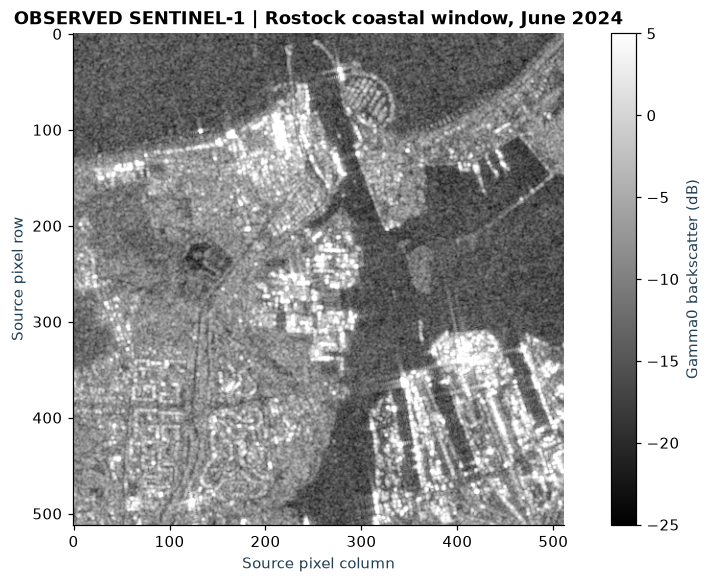

Contains modified Copernicus Sentinel data (2024), processed by Microsoft Planetary Computer.


In [2]:
provenance=json.loads((lab.DATA/"sentinel1_real_window.provenance.json").read_text())
with np.load(lab.DATA/"sentinel1_real_window.npz") as archive:
    real=archive["gamma0_linear"]
real_db=10*np.log10(np.where(real>0,real,np.nan))
display(pd.Series({k:provenance[k] for k in ["item_id","acquired","band","units","center_lon_lat","shape"]}))
fig,ax=plt.subplots()
p=ax.imshow(real_db,cmap="gray",vmin=-25,vmax=5)
ax.set(xlabel="Source pixel column",ylabel="Source pixel row",title="OBSERVED SENTINEL-1 | Rostock coastal window, June 2024")
fig.colorbar(p,ax=ax,label="Gamma0 backscatter (dB)")
plt.show()
print(provenance["attribution"])

## Build an experiment with known targets
The remaining cells use **synthetic pixels**. Exponential speckle approximates a simple single-look intensity model; actual multilooked RTC statistics are more complex. Four bright targets are injected into a variable ocean background. A land mask excludes shoreline returns. Thresholding operates in linear intensity, not dB.

tp            4.000000
fp           19.000000
fn            0.000000
precision     0.173913
recall        1.000000
dtype: float64

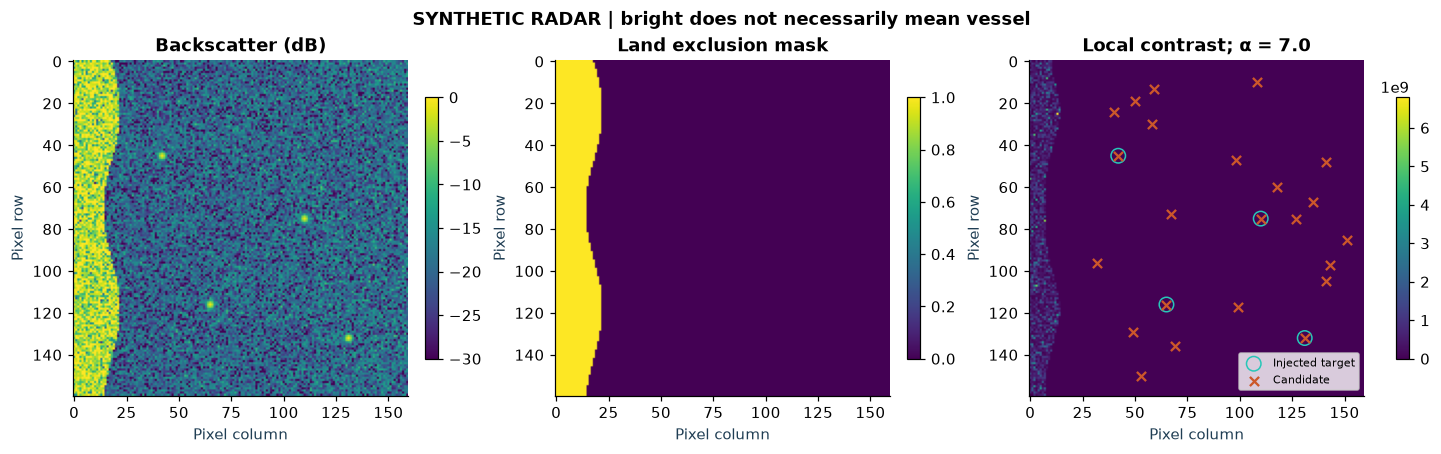

In [3]:
ALPHA=7.0
image,land,truth=lab.radar()
candidates,background=lab.radar_detect(image,land,alpha=ALPHA)
display(pd.Series(lab.detection_metrics(candidates,truth)))
lab.radar_plot(ALPHA); plt.show()

## See the return in 3D
Height is backscatter in decibels, **not ship height**. Drag to inspect the injected target and surrounding speckle.

In [4]:
lab.show(lab.radar_surface())

<iframe title="SYNTHETIC RADAR | a target rising above speckle" srcdoc="<html>
<head><meta charset="utf-8" /></head>
<body>
 <div> <script type="text/javascript">window.PlotlyConfig = {MathJaxConfig: 'local'};</script>
 <script charset="utf-8" src="https://cdn.plot.ly/plotly-3.3.0.min.js" integrity="sha256-bO3dS6yCpk9aK4gUpNELtCiDeSYvGYnK7jFI58NQnHI=" crossorigin="anonymous"></script> <div id="47015ebf-aad2-439f-b67c-668e03315b90" class="plotly-graph-div" style="height:580px; width:100%;"></div> <script type="text/javascript"> window.PLOTLYENV=window.PLOTLYENV || {}; if (document.getElementById("47015ebf-aad2-439f-b67c-668e03315b90")) { Plotly.newPlot( "47015ebf-aad2-439f-b67c-668e03315b90", [{"colorbar":{"title":{"text":"dB"}},"colorscale":[[0.0,"#440154"],[0.1111111111111111,"#482878"],[0.2222222222222222,"#3e4989"],[0.3333333333333333,"#31688e"],[0.4444444444444444,"#26828e"],[0.5555555555555556,"#1f9e89"],[0.6666666666666666,"#35b779"],[0.7777777777777778,"#6ece58"],[0.8888888888888888,"#b5de2b"],[1.0,"#fde725"]],"z":{"dtype":"f8","bdata":"fi7g9zT8P8BKkcd0UrAxwHW8\u002fbdKKTPAUZ3YUmJQMsBh2WSE7DUwwEh69Ain7jnAJJ2yTonUOMA7d7meVjgzwEB6WP31NzXAyMkLPMcOMsA+ctNBJSc8wLnSomN0qzbAgWNWOW0oOcBGYOhBLWY8wEaJ661kZDLATcrukVqYO8ASjUDKz1YzwKLxRJqqAjDAoImD\u002fhRzLMDeZFcGhk01wFfVP7LYRzLAabbNg8SeMcBTF8em+x88wBp5LdG\u002fVjfA\u002fo4Khv4iOMBdzv7iNzkswCEHlJ2+BDbAnPWvHRvwP8Bd5Lkxh9gywHzQeuDsHi7ATHLzMc3wMcCg8o4spqk7wKzU4PcW2znA1AwPxK3nMcDl1fJivD09wJ\u002fA57aKFTPA0ZNQwMwNQsCNO0jq\u002fT00wGTwOycaoTbAaTggSrMhP8D+1ayyEQMqwIOxdH5ZVzTAp0Vh0xZOM8BIY+ZbUJQ2wKVR2p4RCzHAYi2wy1cBMcBQ\u002f1ua30QywJJCu109STHAwCKMhROXN8Dnh\u002fi6lbhDwGDBXvV\u002fnjDA7nDiNJdrL8C0BV9QcIQwwGMKvKRo1jHAlhDm0I+OOsBAjmVhPT8ywMOSLuzmLTbAZihwJJpdP8D+M8YmaW5AwGTqceDHKzLA2\u002fIIZM9jL8BubcxkaMIywPv5RkPajDXAKr4qrMJqMMBRUMab5mAtwFi9Of8HkjbAGu1Ihg7wNMDdhqb+Y301wNJTM4qiHyjAKtB5GPDvMcBLLnpcoNUwwEzxB24X5zPAfykoIY6lNcAMCkiuTXwxwNO5NOC7djPAdR1e5YALM8D28V4uRkQxwE56ZPouDjHAys01INtCM8DaAhZYbJ4uwLavpKyNbzLAGJx4UzsqO8C4v6tzmQ4xwGCd2+nW2yvAllRVfwfvNcAxwoVQigUvwKx5oNMGrjbA0oQK\u002fWuZNMCwP5t7c7E5wJaZ\u002fqoIj0fAdFywjq0wOMD8HiC114Y5wNj411fiUTLA85udcPG\u002fLsBE12DafQQ6wKQYUtgBoD\u002fALwoyJrFqN8D5HwFcpolBwPRHThOJlDLA7J1LmZPoOcCrw97N9rswwJGy+HY3\u002fjbA1TSOEBbWMcCgxzDHlKAzwGnszoAZQTDA6r598\u002filKcCekYJwNvIvwJ4RvXn4KDLAju1s1MwSN8AV85KeU5QvwISrF1+jqTXAVu4CdlpoMsCyNduPbbc1wLwFEzhzJCnA7WNn6k70M8DmCbE4\u002faMwwGlsp6jlsj\u002fAjIBc3mYePMB80JjlzDQswNY5ieIURDXAp8OSkQVuMMBi\u002fjgLN8wzwNJg6nNSiUPA7zC2k4pSOcBIh62ImU4xwEAzSGu0YTzAESipJesmPMDCOk\u002fz8mU4wMoF7PFgACjAYSo5+FAxNsDB92v6Kkk2wG5bVje6lzHAyt\u002fBEIJkM8AyTpbG++4ywLEo96E+NDnA2z9UeLtoMcDaqRLsoIUuwNkbeecxYDTAjs8Am2pQM8CeBDkSpNwxwCr66BzVEDTAblKj0nwpRMD2AjpUSxA6wES24MlYZi3ATgRcNbI5McB5VgFJTLcuwG5WKNTMxS7ArS1G5beZMsAa5dj6zt8twFImb\u002fYtJjfAeB3SBFspLcCkvg+HnDI7wJkJ4Jme\u002fC\u002fAjreZcK94LcB8MLU+wrM4wMYWDMcSgDnAoiblJMtjM8DjPzYnm0BAwDJA0aa1EzDAc\u002frppN2KOcCeoUK3iI8zwJRXY6ZhfDfAT4FLXlYNMMChpXRHMKQuwFejPRBd7jLAJIOBjkd4N8DdVD0Y0WA0wNK+D2RGWjLAzyKxCpWGKcCIMjhfvsEywCa1zz5KFTDAFaU6D4QqMsBdXSNbVK8uwKguqBUlZkLA50nD+0FZNcBJkrWqjhcxwDTbAZFG9DvARbINHsmYO8DE\u002fF3oD+QswMwhPIVhfi7AqQOBcveXMMBCxDsDwNovwCpAVWKgBS\u002fAq053V78RM8D6mZfU+0c5wDPg3NPo8zLAhb80+\u002fsFMsDaJ+WfObUwwIoK3LCB6jbAo4S3DcHxMMA1hhqpFGQ3wE6lPUs75TPALQ\u002fRi67XMcCez8OOqoc1wMjWvlRaiTbAzUEpO1ZYM8AFIU2Y8KMtwK9RjvoGuyzAKavyiATzN8BTfnZys2c2wE62fPi8kTHAJBl9UELWMMAXS\u002fdRuA8zwO2oCUH2xDTAYbX+OgaRPMAjHovocmkwwBzErFUW+TDAbiE7PZfUMsAG1681Zbc4wE+1Csxw8CzA0kouUHCEMsCJqgftH3c8wEOYCxErPTLA6A8T7fYyLMDq+YtOn9czwKOMGKV+uTfArps\u002fMCIHNMBgIVdYpVMzwK1aMrM36zvAuT+jKP5yMsDaYASUl+QswAH3Y9cDEz\u002fAog1sWJxuNsCSCyxyjpU0wIHYF6xqFjfAvALKIGeWM8Af2Avfh085wPNNKiergC\u002fAi4FC+uGKMMB29uv+VioywAyWVoVcxzDAV88ARGvRMMAWmsjP0m82wHa5wyRcbzTA18G5qNK0McBW8pQe+QUywGoiJYibwjbAJauwY1n8M8A3lJ6ApSQ6wAa11b3qFSnA8K6rU19FMMC00nkG5fAvwO3yKCLDv0HA9hTVKsGcNMDZxIW4+Y88wHCXJADgcyvAsxp852x8RsBbY+eezJIuwK2FwLhmDzrAmkoe+Kk2QMAKht\u002fTdvQwwI8Ab0wFDjHAhsxff\u002f1zM8D0o24HqvIxwM+QgkelezXAil3f2ippMsBKfs7+Or0twGx8Czrk3j\u002fAcw2J6Lj\

## Precision, recall and the price of a threshold
Candidates are local maxima. We match them one-to-one to injected target centers within three pixels. A duplicate candidate cannot count as a second true positive. These scores describe this toy image only; they do not estimate real-world ship detection performance.

,alpha,tp,fp,fn,precision,recall
0,3,4,504,0,0.007874,1.0
1,4,4,266,0,0.014815,1.0
2,5,4,109,0,0.035398,1.0
3,6,4,45,0,0.081633,1.0
4,7,4,19,0,0.173913,1.0
5,8,4,6,0,0.400000,1.0
6,10,4,1,0,0.800000,1.0
7,14,4,0,0,1.000000,1.0
8,20,4,0,0,1.000000,1.0
9,40,4,0,0,1.000000,1.0


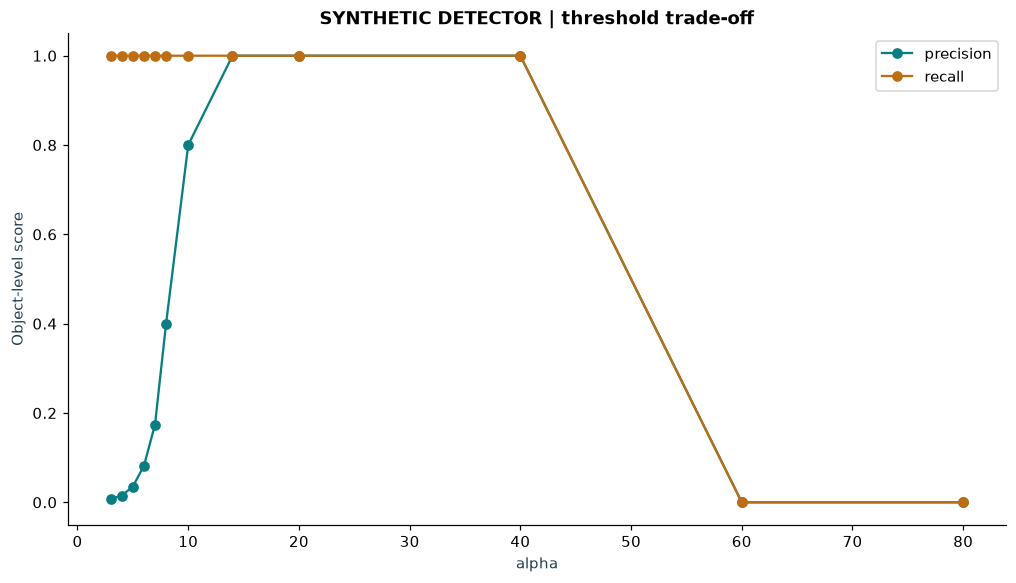

In [5]:
rows=[]
for alpha in [3,4,5,6,7,8,10,14,20,40,60,80]:
    points,_=lab.radar_detect(image,land,alpha=alpha)
    rows.append({"alpha":alpha,**lab.detection_metrics(points,truth)})
scores=pd.DataFrame(rows)
display(scores)
ax=scores.plot(x="alpha",y=["precision","recall"],marker="o",color=["#087e83","#bd6e13"])
ax.set(ylim=(-.05,1.05),ylabel="Object-level score",title="SYNTHETIC DETECTOR | threshold trade-off")
plt.show()

## What would make a real detector credible?
We would need a trustworthy land/infrastructure mask, sensor-specific calibration, labeled independent scenes, vessel-size and sea-state strata, coverage accounting, and validation of both false alarms and missed vessels. The toy detector is not applied to the real crop as a validated ship classifier. Inspect the actual crop and explain why a simple brightness rule would confuse the harbor with vessels.

**Extension:** `scripts/fetch_sar_window.py` extracts another small calibrated window locally. It uses range reads, never loads a full gigabyte-scale scene, and records provenance. New extractions change the evidence; retain the original file and its citation when comparing.